In [4]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

np.set_printoptions(precision=6,suppress=True)

DATA_DIR = Path("dataset")
IMAGE_DIR = DATA_DIR/"images"

PET_DEV = [f"pet_{i:02d}" for i in (1, 3, 5, 7, 9, 11)]
PET_TEST = [f"pet_{i:02d}" for i in (2, 4, 6, 8, 10, 12)]
CAM_DEV = [f"camouflage_{i:02d}" for i in (1, 2, 3)]
CAM_TEST = [f"camouflage_{i:02d}" for i in (4, 5, 6)]

DEV = PET_DEV + CAM_DEV
TEST = PET_TEST + CAM_TEST
ALL_IMAGES = PET_DEV + PET_TEST + CAM_DEV + CAM_TEST

In [6]:
public = np.load(DATA_DIR / "public_inputs.npz")
evaluation = np.load(DATA_DIR / "evaluation_masks.npz")
thin_data = np.load(DATA_DIR / "thin_structures.npz")

images = {
    image_id: np.asarray(Image.open(IMAGE_DIR / f"{image_id}.png"), dtype=np.float64) / 255.0
    for image_id in ALL_IMAGES
}
anchors = {image_id: public[f"{image_id}_anchors"] for image_id in ALL_IMAGES}
eligible = {image_id: public[f"{image_id}_eligible"] for image_id in ALL_IMAGES}
truth = {image_id: evaluation[f"{image_id}_truth"] for image_id in ALL_IMAGES}
patch_truth = {image_id: evaluation[f"{image_id}_patch_truth"] for image_id in ALL_IMAGES}

print(len(images), "images")
print(images["pet_01"].shape, truth["pet_01"].shape)
print("anchors pet_01:", np.unique(anchors["pet_01"], return_counts=True))

18 images
(96, 128, 3) (96, 128)
anchors pet_01: (array([-1,  0,  1]), array([760,   4,   4]))


In [10]:
PATCH_ROWS, PATCH_COLS = 24,32
N_PATCHES = PATCH_ROWS * PATCH_COLS

def patch_mean_rgb(image):
    return (image.reshape(PATCH_ROWS,4,PATCH_COLS,4,3).mean(axis=(1,3)).reshape(N_PATCHES,3))

_patch_r, _patch_c = np.mgrid[0:PATCH_ROWS,0:PATCH_COLS]
PATCH_POSITION = np.stack([0.25*_patch_r/23,0.25*_patch_c/31],axis=-1).reshape(N_PATCHES,2)

def colour_position_features(image):
    return np.concatenate([patch_mean_rgb(image),PATCH_POSITION], axis=1)

def expand_patch_mask(patch_mask):
    grid = np.asarray(patch_mask).reshape(PATCH_ROWS,PATCH_COLS)
    return np.repeat(np.repeat(grid, 4, axis=0),4,axis=1)

def mask_scores(patch_mask,image_id):
    reference = truth[image_id]
    predicted = expand_patch_mask(patch_mask)
    valid = reference != -1
    P = (predicted==1)&valid
    T = (reference==1)&valid
    intersection = int(np.sum(P&T))
    union = int(np.sum(P|T))
    iou = 1.0 if union == 0 else intersection/union
    recall = 0.0 if T.sum() == 0 else intersection/T.sum()
    false_positives =  int(np.sum(P&~T))
    return iou,recall,false_positives

def group_mean(values, image_ids):
    return np.mean([values[image_id] for image_id in image_ids])

In [11]:
feat = colour_position_features(images["pet_01"])
print(feat.shape)
print(feat[:3])
print(expand_patch_mask(np.arange(N_PATCHES)).shape)

(768, 5)
[[0.591422 0.577451 0.543137 0.       0.      ]
 [0.618382 0.610784 0.572059 0.       0.008065]
 [0.627696 0.619853 0.580882 0.       0.016129]]
(96, 128)


In [15]:
def logsumexp(a, axis=None):
    a = np.asarray(a, dtype=np.float64)
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m),m,0.0)
    out = np.log(np.sum(np.exp(a-m),axis=axis, keepdims=True))+m
    return np.squeeze(out,axis=axis)

def log_gaussian(X, mean, cov):
    d = X.shape[1]
    L = np.linalg.cholesky(cov)
    solved = np.linalg.solve(L,(X-mean).T)
    quadratic = np.sum(solved**2, axis =0)
    log_det = 2.0 * np.sum(np.log(np.diag(L)))
    return -0.5 * (d * np.log(2.0 * np.pi) + log_det + quadratic)

def _log_probabilities(X, weights, means, covs):
    n, K = X.shape[0], len(weights)
    logp = np.empty((n, K), dtype=np.float64)
    for k in range(K):
        if weights[k] == 0.0:
            logp[:, k] = -np.inf
        else:
            logp[:, k] = np.log(weights[k]) + log_gaussian(X, means[k], covs[k])
    return logp

def _e_step(X, weights, means, covs, component_class, labels):
    logp = _log_probabilities(X, weights, means, covs)
    n, K = logp.shape
    responsibilities = np.zeros((n, K), dtype=np.float64)
    for label in (-1, 0, 1):
        rows = np.where(labels == label)[0]
        if rows.size == 0:
            continue
        if label == -1:
            cols = np.arange(K)
        else:
            cols = np.where(component_class == label)[0]
        cols = cols[weights[cols] > 0.0]
        if cols.size == 0:
            continue
        block = logp[np.ix_(rows, cols)]
        responsibilities[np.ix_(rows, cols)] = np.exp(
            block - logsumexp(block, axis=1)[:, None]
        )
    return responsibilities

def _log_likelihood(X, weights, means, covs, component_class, labels):
    logp = _log_probabilities(X, weights, means, covs)
    total = 0.0
    unlabelled = np.where(labels == -1)[0]
    if unlabelled.size > 0:
        total += logsumexp(logp[unlabelled], axis=1).sum()
    for label in (0, 1):
        rows = np.where(labels == label)[0]
        if rows.size == 0:
            continue
        cols = np.where((component_class == label) & (weights > 0.0))[0]
        if cols.size == 0:
            continue
        total += logsumexp(logp[np.ix_(rows, cols)], axis=1).sum()
    return total

def fit_gmm(X, initial_means, component_class, labels, n_updates):
    X = np.asarray(X, dtype=np.float64)
    labels = np.asarray(labels)
    component_class = np.asarray(component_class)
    n, d = X.shape
    K = len(initial_means)
    weights = np.full(K, 1.0 / K, dtype=np.float64)
    means = np.array(initial_means, dtype=np.float64)
    diff = X - X.mean(axis=0)
    shared_cov = diff.T @ diff / n + 1e-4 * np.eye(d)
    covs = np.repeat(shared_cov[None], K, axis=0)
    trace = [_log_likelihood(X, weights, means, covs, component_class, labels)]
    for _ in range(n_updates):
        responsibilities = _e_step(
            X, weights, means, covs, component_class, labels
        )
        Nk = responsibilities.sum(axis=0)
        new_weights = Nk / n
        new_means = means.copy()
        new_covs = covs.copy()
        for k in range(K):
            if Nk[k] == 0.0:
                new_weights[k] = 0.0
                continue
            new_means[k] = (responsibilities[:, k, None] * X).sum(axis=0) / Nk[k]
            diff = X - new_means[k]
            new_covs[k] = ((responsibilities[:, k, None] * diff).T @ diff / Nk[k]+ 1e-4 * np.eye(d))
        weights, means, covs = new_weights, new_means, new_covs
        trace.append(_log_likelihood(X, weights, means, covs, component_class, labels))
    final_responsibilities = _e_step(X, weights, means, covs, component_class, labels)
    return weights, means, covs, final_responsibilities, np.array(trace)

In [16]:
X_check = np.array(
    [
        [-1.0, -0.2],
        [-0.8, 0.3],
        [-0.1, -0.2],
        [0.2, 0.1],
        [0.8, -0.3],
        [1.0, 0.3],
    ]
)
labels_check = np.array([0, -1, -1, -1, -1, 1])
initial_means_check = np.array([[-0.8, 0.0], [0.8, 0.0]])
component_class_check = np.array([0, 1])

weights_c, means_c, covs_c, resp_c, trace_c = fit_gmm(
    X_check,
    initial_means_check,
    component_class_check,
    labels_check,
    n_updates=3,
)

print("log-likelihood trace:")
print(trace_c)
print("\nweights:", weights_c)
print("\nmeans:\n", means_c)
print("\ncovariances:\n", covs_c)
print("\nresponsibilities:\n", resp_c)

print("\nlargest row sum:", resp_c.sum(axis=1).max())
print("smallest row sum:", resp_c.sum(axis=1).min())

wrong_class_nonzero = 0
for i, label in enumerate(labels_check):
    if label == -1:
        continue
    wrong_cols = np.where(component_class_check != label)[0]
    wrong_class_nonzero += int(np.sum(resp_c[i, wrong_cols] > 0.0))

print("labelled points with non-zero wrong-class responsibility:", wrong_class_nonzero)

log-likelihood trace:
[-7.621063 -6.204596 -6.066172 -6.046396]

weights: [0.479744 0.520256]

means:
 [[-0.627169 -0.002359]
 [ 0.610367  0.002175]]

covariances:
 [[[ 0.184626 -0.010351]
  [-0.010351  0.055221]]

 [[ 0.161467  0.026074]
  [ 0.026074  0.064589]]]

responsibilities:
 [[1.       0.      ]
 [0.999438 0.000562]
 [0.626366 0.373634]
 [0.196377 0.803623]
 [0.006567 0.993433]
 [0.       1.      ]]

largest row sum: 1.0
smallest row sum: 1.0
labelled points with non-zero wrong-class responsibility: 0


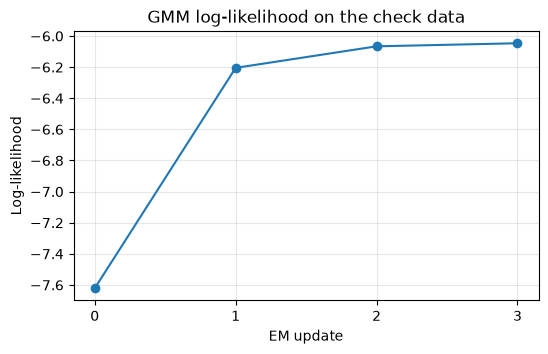

In [17]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(np.arange(len(trace_c)), trace_c, marker="o", linewidth=1.5)
ax.set_xlabel("EM update")
ax.set_ylabel("Log-likelihood")
ax.set_title("GMM log-likelihood on the check data")
ax.set_xticks(np.arange(len(trace_c)))
ax.grid(alpha=0.3)
plt.show()

In [18]:
COMPONENT_CLASS = np.array([0, 0, 0, 1, 1, 1])

def anchor_initial_means(image_id, features):
    anchor_labels = anchors[image_id]
    background = np.where(anchor_labels == 0)[0][:3]
    foreground = np.where(anchor_labels == 1)[0][:3]
    return features[np.concatenate([background, foreground])]

def fit_standard_gmm(image_id, features, n_updates=30):
    features = np.asarray(features, dtype=np.float64)
    initial_means = anchor_initial_means(image_id, features)
    return fit_gmm(
        features,
        initial_means,
        COMPONENT_CLASS,
        anchors[image_id],
        n_updates=n_updates,
    )

def foreground_probability(responsibilities):
    return responsibilities[:, 3:6].sum(axis=1)

def predict_from_responsibilities(image_id, responsibilities):
    probability = foreground_probability(responsibilities)
    prediction = (probability > 0.5).astype(int)
    known = anchors[image_id] >= 0
    prediction[known] = anchors[image_id][known]
    return prediction, probability

In [19]:
gmm_colour = {}

for image_id in ALL_IMAGES:
    features = colour_position_features(images[image_id])
    weights_g, means_g, covs_g, resp_g, trace_g = fit_standard_gmm(image_id, features)
    mask_g, prob_g = predict_from_responsibilities(image_id, resp_g)
    iou_g, recall_g, fp_g = mask_scores(mask_g, image_id)
    gmm_colour[image_id] = {
        "features": features,
        "weights": weights_g,
        "means": means_g,
        "covs": covs_g,
        "responsibilities": resp_g,
        "trace": trace_g,
        "prob": prob_g,
        "mask": mask_g,
        "iou": iou_g,
        "recall": recall_g,
        "fp": fp_g,
    }

print("fitted", len(gmm_colour), "images")
print("all traces non-decreasing:",all(np.diff(gmm_colour[i]["trace"]).min() > -1e-9 for i in ALL_IMAGES))

fitted 18 images
all traces non-decreasing: True


In [20]:
print(f"{'Image':<16}{'IoU':>8}{'Recall':>9}")
print("-" * 33)

for image_id in TEST:
    result = gmm_colour[image_id]
    print(f"{image_id:<16}{result['iou']:8.4f}{result['recall']:9.4f}")

groups = [
    ("development pets", PET_DEV),
    ("test pets", PET_TEST),
    ("development camouflage", CAM_DEV),
    ("test camouflage", CAM_TEST),
]
print()
print(f"{'Group':<26}{'Mean IoU':>10}")
print("-" * 36)

for group_name, image_ids in groups:
    mean_iou = np.mean([gmm_colour[i]["iou"] for i in image_ids])
    print(f"{group_name:<26}{mean_iou:10.4f}")

Image                IoU   Recall
---------------------------------
pet_02            0.3428   0.8247
pet_04            0.3350   0.6658
pet_06            0.7741   0.7741
pet_08            0.6965   1.0000
pet_10            0.9557   1.0000
pet_12            0.7900   0.9703
camouflage_04     0.4589   0.6970
camouflage_05     0.5000   0.7531
camouflage_06     0.4508   0.8277

Group                       Mean IoU
------------------------------------
development pets              0.4876
test pets                     0.6490
development camouflage        0.3765
test camouflage               0.4699


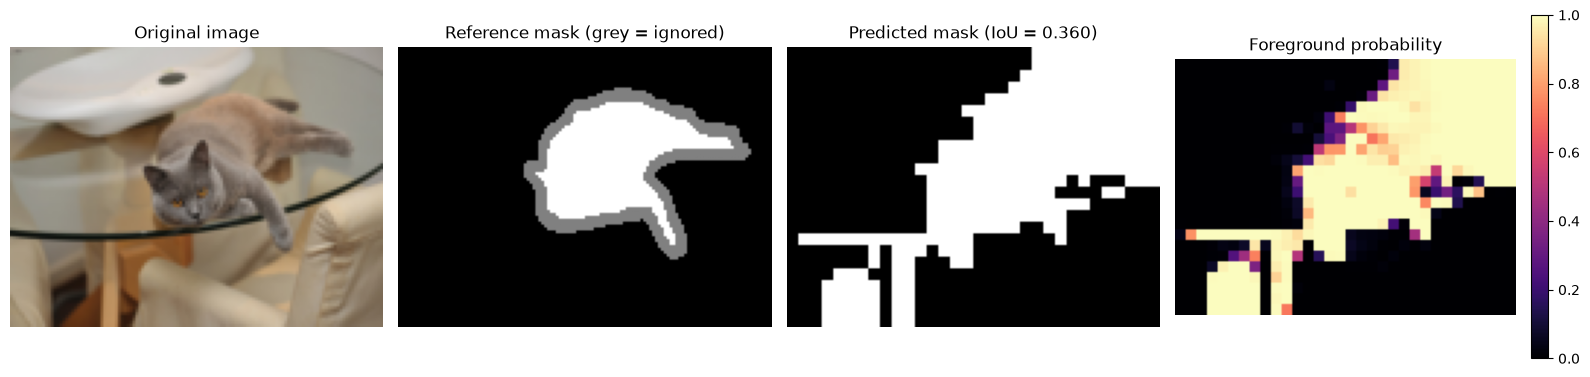

In [21]:
image_id = "pet_01"
result = gmm_colour[image_id]
reference_display = np.where(truth[image_id] == -1, 0.5, truth[image_id])
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(images[image_id])
axes[0].set_title("Original image")
axes[1].imshow(reference_display, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Reference mask (grey = ignored)")
axes[2].imshow(expand_patch_mask(result["mask"]), cmap="gray", vmin=0, vmax=1)
axes[2].set_title(f"Predicted mask (IoU = {result['iou']:.3f})")
probability_map = expand_patch_mask(result["prob"])
im = axes[3].imshow(probability_map, cmap="magma", vmin=0, vmax=1)
axes[3].set_title("Foreground probability")
fig.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)
for ax in axes:
    ax.axis("off")

fig.tight_layout()
plt.show()